<div align="center">

# **HASIL ANALISIS 5 STUDI KASUS GEOFISIKA**
#### **Nama: Sulfiani**  
#### **NIM: H061241033**  
#### **Mata Kuliah: Kecerdasan Artifisial Geofisika**

---
</div>



## **1. Studi Kasus GPR — Identifikasi Pipa Bawah Permukaan**

Metode Ground Penetrating Radar (GPR) memancarkan gelombang elektromagnetik ke bawah permukaan dan merekam pantulan akibat perubahan sifat elektromagnetik material. Pada lintasan sepanjang 50 m dengan antena 500 MHz, ditemukan dua anomali hiperbola, yaitu pada jarak 18 m dengan waktu tempuh dua arah (two-way travel time/TWT) 12 ns dan pada jarak 34 m dengan TWT 18 ns. Dengan kecepatan gelombang 0,10 m/ns, kedalaman perkiraan dihitung menggunakan \(z=v t/2\). Anomali pertama diperkirakan berada pada kedalaman 0,60 m, sedangkan anomali kedua sekitar 0,90 m.

Pola hiperbola dapat berkaitan dengan objek terlokalisasi seperti pipa, tetapi tidak cukup untuk memastikan jenis objek secara tunggal. Pipa merupakan salah satu kemungkinan interpretasi; benda tertanam atau batas material yang menghasilkan kontras elektromagnetik juga dapat membentuk refleksi serupa. Kondisi perkerasan dan karakteristik radargram lengkap perlu diperiksa sebelum menetapkan target sebagai pipa. Plot berikut hanya menandai dua posisi anomali berdasarkan data soal.

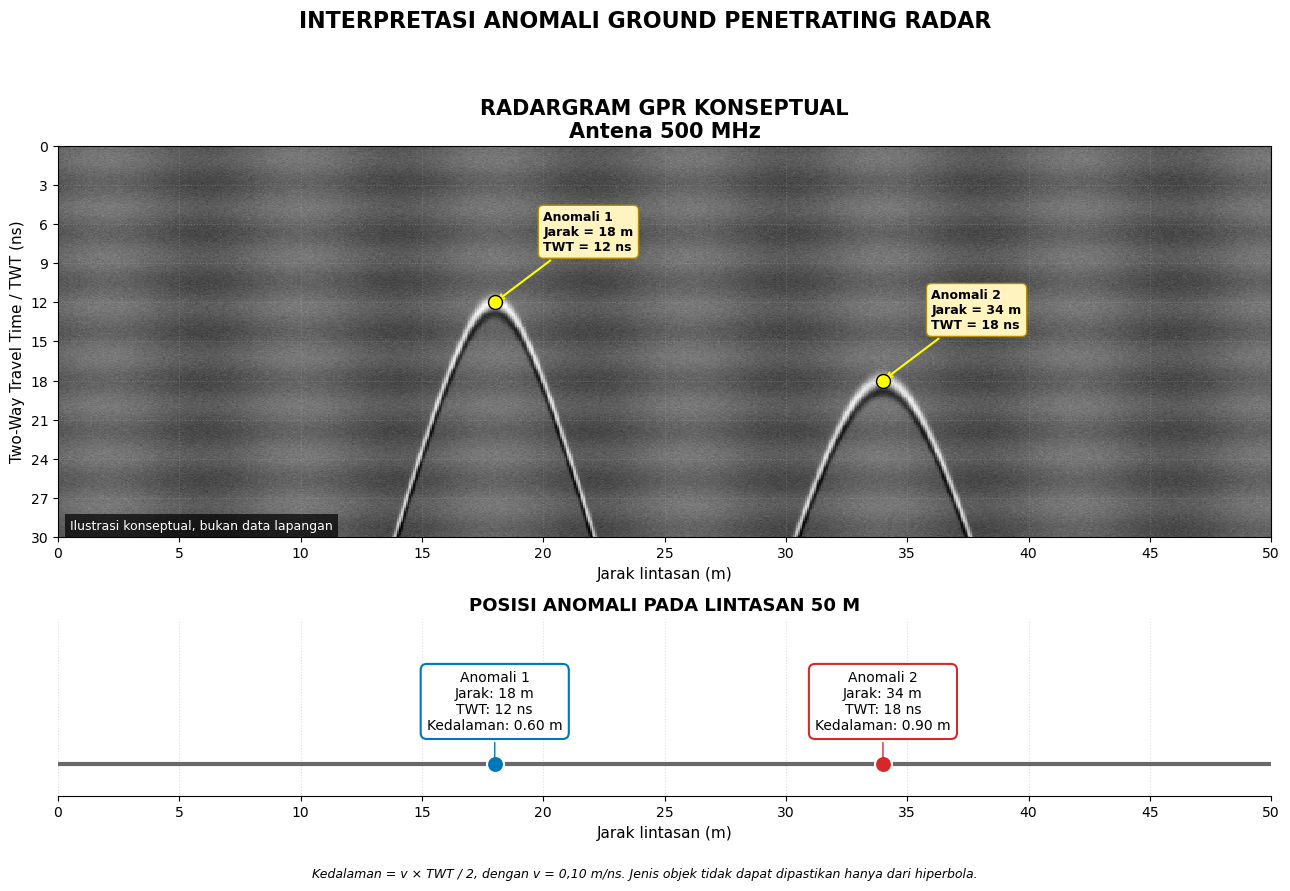

HASIL INTERPRETASI GPR

Anomali 1
Posisi     : 18 m
TWT        : 12 ns
Kedalaman  : 0.60 m

Anomali 2
Posisi     : 34 m
TWT        : 18 ns
Kedalaman  : 0.90 m


In [3]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETER SURVEI GPR
# ==========================================
panjang_lintasan = 50  # meter
frekuensi_antena = 500  # MHz
kecepatan = 0.10  # m/ns

# Data dua anomali
posisi = np.array([18, 34])  # meter
twt = np.array([12, 18])     # ns

# Hitung kedalaman: z = v * TWT / 2
kedalaman = kecepatan * twt / 2

# ==========================================
# 2. MEMBUAT RADARGRAM KONSEPTUAL
# ==========================================
x = np.linspace(0, panjang_lintasan, 700)
waktu = np.linspace(0, 30, 420)
X, T = np.meshgrid(x, waktu)

# Latar radargram ilustratif
rng = np.random.default_rng(7)
radargram = (
    0.10 * np.sin(2 * np.pi * X / 8)
    + 0.07 * np.sin(2 * np.pi * T / 3.8)
    + 0.035 * rng.normal(size=X.shape)
)

# Membentuk dua refleksi hiperbola ilustratif
for x0, t0 in zip(posisi, twt):
    t_hyperbola = np.sqrt(
        t0**2 + (2 * (X - x0) / kecepatan / 3)**2
    )

    radargram += 0.9 * np.exp(
        -((T - t_hyperbola) / 0.55)**2
    )
    radargram -= 0.55 * np.exp(
        -((T - (t_hyperbola + 0.8)) / 0.45)**2
    )

# ==========================================
# 3. MEMBUAT FIGUR
# ==========================================
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(13, 9),
    gridspec_kw={"height_ratios": [2.2, 1]}
)

# ==========================================
# 4. PLOT RADARGRAM
# ==========================================
ax1.pcolormesh(
    X, T, radargram,
    cmap="gray",
    shading="auto"
)

ax1.set_title(
    "RADARGRAM GPR KONSEPTUAL\n"
    "Antena 500 MHz",
    fontsize=15,
    fontweight="bold"
)

ax1.set_xlabel("Jarak lintasan (m)", fontsize=11)
ax1.set_ylabel("Two-Way Travel Time / TWT (ns)", fontsize=11)

ax1.set_xlim(0, panjang_lintasan)
ax1.set_ylim(30, 0)
ax1.set_xticks(np.arange(0, 51, 5))
ax1.set_yticks(np.arange(0, 31, 3))
ax1.grid(linestyle=":", alpha=0.3)

# Menandai posisi anomali
for i, (x0, t0, z0) in enumerate(
    zip(posisi, twt, kedalaman), start=1
):
    ax1.scatter(
        x0, t0,
        s=100,
        color="yellow",
        edgecolor="black",
        zorder=5
    )

    ax1.annotate(
        f"Anomali {i}\n"
        f"Jarak = {x0} m\n"
        f"TWT = {t0} ns",
        xy=(x0, t0),
        xytext=(x0 + 2, t0 - 4),
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="#fff3bf",
            edgecolor="#b38f00"
        ),
        arrowprops=dict(
            arrowstyle="->",
            color="yellow",
            linewidth=1.5
        )
    )

ax1.text(
    0.01, 0.02,
    "Ilustrasi konseptual, bukan data lapangan",
    transform=ax1.transAxes,
    color="white",
    fontsize=9,
    bbox=dict(facecolor="black", alpha=0.7, edgecolor="none")
)

# ==========================================
# 5. PLOT POSISI ANOMALI
# ==========================================
ax2.hlines(
    0, 0, panjang_lintasan,
    color="dimgray",
    linewidth=3
)

warna = ["#0077b6", "#d62828"]

for i, (x0, t0, z0, c) in enumerate(
    zip(posisi, twt, kedalaman, warna), start=1
):
    ax2.scatter(
        x0, 0,
        s=150,
        color=c,
        edgecolor="white",
        linewidth=1.5,
        zorder=3
    )

    ax2.annotate(
        f"Anomali {i}\n"
        f"Jarak: {x0} m\n"
        f"TWT: {t0} ns\n"
        f"Kedalaman: {z0:.2f} m",
        xy=(x0, 0),
        xytext=(x0, 0.25),
        ha="center",
        va="bottom",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.45",
            facecolor="white",
            edgecolor=c,
            linewidth=1.5
        ),
        arrowprops=dict(
            arrowstyle="-",
            color=c
        )
    )

ax2.set_title(
    "POSISI ANOMALI PADA LINTASAN 50 M",
    fontsize=13,
    fontweight="bold"
)

ax2.set_xlabel("Jarak lintasan (m)", fontsize=11)
ax2.set_xlim(0, 50)
ax2.set_ylim(-0.25, 1.15)
ax2.set_yticks([])
ax2.set_xticks(np.arange(0, 51, 5))
ax2.grid(axis="x", linestyle=":", alpha=0.4)

for sisi in ["left", "right", "top"]:
    ax2.spines[sisi].set_visible(False)

# ==========================================
# 6. KETERANGAN DAN SIMPAN GAMBAR
# ==========================================
fig.suptitle(
    "INTERPRETASI ANOMALI GROUND PENETRATING RADAR",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.5, 0.015,
    "Kedalaman = v × TWT / 2, dengan v = 0,10 m/ns. "
    "Jenis objek tidak dapat dipastikan hanya dari hiperbola.",
    ha="center",
    fontsize=9,
    style="italic"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])

plt.savefig(
    "plot_anomali_GPR_konseptual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 7. MENAMPILKAN HASIL PERHITUNGAN
# ==========================================
print("HASIL INTERPRETASI GPR")

for i, (x0, t0, z0) in enumerate(
    zip(posisi, twt, kedalaman), start=1
):
    print(f"\nAnomali {i}")
    print(f"Posisi     : {x0} m")
    print(f"TWT        : {t0} ns")
    print(f"Kedalaman  : {z0:.2f} m")


## **2. Metode Seismik Refraksi — Ketebalan Lapisan dan Kedalaman Batuan Dasar**

Seismik refraksi menafsirkan struktur bawah permukaan melalui hubungan antara jarak sumber–geofon dan waktu kedatangan gelombang. Kemiringan kurva waktu-tempuh berbanding terbalik dengan kecepatan, sehingga kecepatan gelombang langsung 400 m/s, refraksi pertama 1.200 m/s, dan refraksi kedua 2.500 m/s menunjukkan peningkatan kecepatan ke lapisan yang lebih dalam. Hal ini dapat mencerminkan material yang semakin kompak atau lebih terkonsolidasi, tetapi jenis material tidak dapat dipastikan hanya dari kecepatan.

Soal menyebutkan 12 geofon dengan interval 5 m dan tiga lapisan interpretasi, tetapi tidak memberikan waktu tiba numerik maupun waktu intersep. Karena itu, kedalaman batas lapisan dan ketebalan lapisan tidak dapat dihitung secara andal dari informasi yang tersedia. Plot di bawah merupakan ilustrasi garis waktu-tempuh ideal dengan hubungan \(t=x/v\), bukan kurva hasil pengukuran; garis ini hanya menunjukkan perbedaan kemiringan akibat kecepatan yang diberikan.

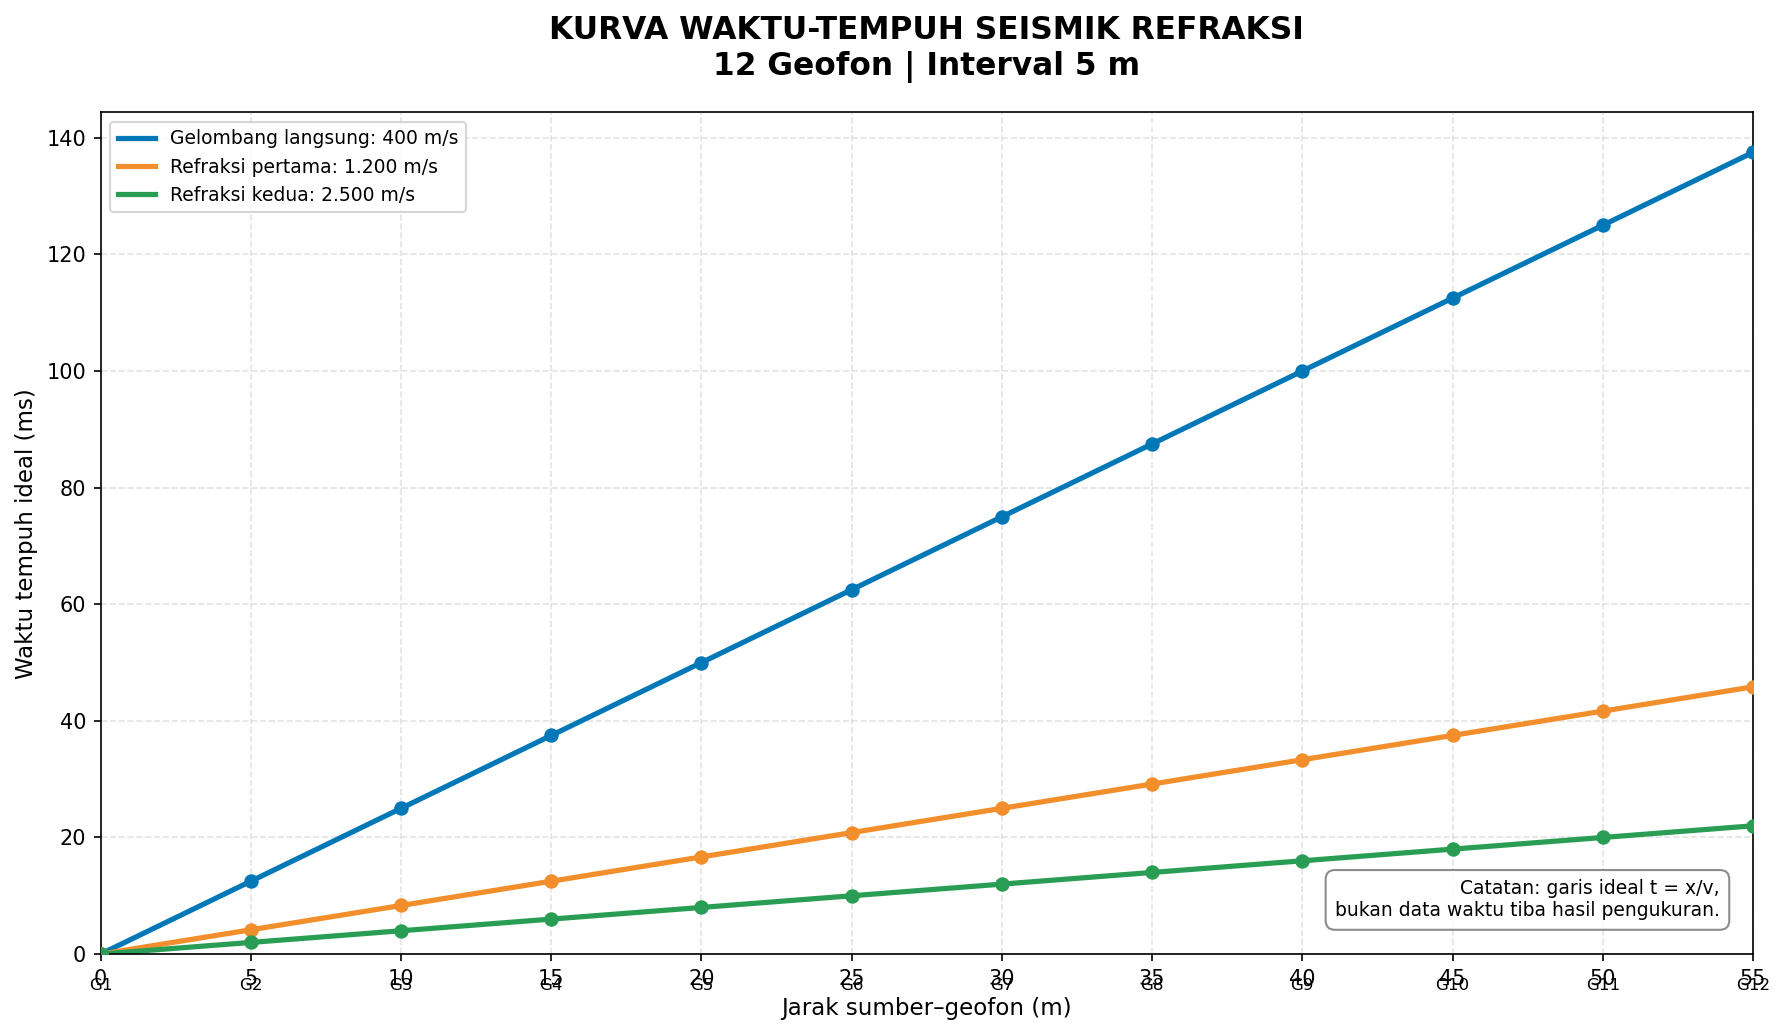

HASIL INTERPRETASI SEISMIK REFRAKSI
Jumlah geofon       : 12
Interval geofon     : 5 m
Panjang bentangan   : 55 m

Kecepatan gelombang:
Lapisan 1            : 400 m/s
Lapisan 2            : 1200 m/s
Lapisan 3            : 2500 m/s

Interpretasi:
1. Gelombang langsung memiliki kecepatan 400 m/s. Kecepatan ini paling rendah di antara ketiga nilai.
2. Refraksi pertama memiliki kecepatan 1.200 m/s, lebih tinggi daripada gelombang langsung.
3. Refraksi kedua memiliki kecepatan 2.500 m/s, yang merupakan kecepatan tertinggi.
4. Peningkatan kecepatan dapat menunjukkan material yang semakin kompak atau terkonsolidasi.
5. Jenis material tidak dapat dipastikan hanya dari kecepatan gelombang.
6. Kedalaman dan ketebalan lapisan belum dapat ditentukan tanpa waktu tiba aktual dan analisis kurva waktu-tempuh.


In [5]:

import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# 1. PARAMETER SURVEI SEISMIK REFRAKSI
# =====================================================
jumlah_geofon = 12
interval_geofon = 5  # meter

# Posisi geofon sepanjang lintasan
jarak = np.arange(jumlah_geofon) * interval_geofon
panjang_lintasan = jarak[-1]

# Kecepatan gelombang setiap lapisan
v1 = 400    # m/s: gelombang langsung
v2 = 1200   # m/s: refraksi pertama
v3 = 2500   # m/s: refraksi kedua

# =====================================================
# 2. MENGHITUNG WAKTU TEMPUH IDEAL
# t = x / v
# Konversi detik menjadi milidetik
# =====================================================
waktu1 = (jarak / v1) * 1000
waktu2 = (jarak / v2) * 1000
waktu3 = (jarak / v3) * 1000

# Garis halus untuk plot
x_halus = np.linspace(0, panjang_lintasan, 300)

t1_halus = (x_halus / v1) * 1000
t2_halus = (x_halus / v2) * 1000
t3_halus = (x_halus / v3) * 1000

# =====================================================
# 3. MEMBUAT GRAFIK
# =====================================================
fig, ax = plt.subplots(figsize=(12, 7), dpi=150)

# Kurva waktu-tempuh ideal
ax.plot(
    x_halus, t1_halus,
    color="#0077b6", linewidth=2.5,
    label="Gelombang langsung: 400 m/s"
)

ax.plot(
    x_halus, t2_halus,
    color="#f28e2b", linewidth=2.5,
    label="Refraksi pertama: 1.200 m/s"
)

ax.plot(
    x_halus, t3_halus,
    color="#2a9d55", linewidth=2.5,
    label="Refraksi kedua: 2.500 m/s"
)

# Titik posisi geofon pada setiap garis ideal
ax.scatter(
    jarak, waktu1,
    color="#0077b6", s=35, zorder=3
)
ax.scatter(
    jarak, waktu2,
    color="#f28e2b", s=35, zorder=3
)
ax.scatter(
    jarak, waktu3,
    color="#2a9d55", s=35, zorder=3
)

# Label nomor geofon di sepanjang lintasan
for i, x in enumerate(jarak, start=1):
    ax.annotate(
        f"G{i}",
        xy=(x, 0),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="black"
    )

# =====================================================
# 4. FORMAT GRAFIK
# =====================================================
ax.set_title(
    "KURVA WAKTU-TEMPUH SEISMIK REFRAKSI\n"
    "12 Geofon | Interval 5 m",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Jarak sumber–geofon (m)", fontsize=11)
ax.set_ylabel("Waktu tempuh ideal (ms)", fontsize=11)

ax.set_xlim(0, panjang_lintasan)
ax.set_ylim(bottom=0)

ax.set_xticks(jarak)
ax.grid(True, linestyle="--", alpha=0.35)

ax.legend(
    loc="upper left",
    fontsize=9,
    frameon=True
)

# Catatan pada grafik
ax.text(
    0.98, 0.04,
    "Catatan: garis ideal t = x/v,\n"
    "bukan data waktu tiba hasil pengukuran.",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

plt.tight_layout()
plt.savefig(
    "plot_seismik_refraksi.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# =====================================================
# 5. INTERPRETASI OTOMATIS
# =====================================================
print("=" * 55)
print("HASIL INTERPRETASI SEISMIK REFRAKSI")
print("=" * 55)

print(f"Jumlah geofon       : {jumlah_geofon}")
print(f"Interval geofon     : {interval_geofon} m")
print(f"Panjang bentangan   : {panjang_lintasan} m")

print("\nKecepatan gelombang:")
print(f"Lapisan 1            : {v1} m/s")
print(f"Lapisan 2            : {v2} m/s")
print(f"Lapisan 3            : {v3} m/s")

print("\nInterpretasi:")
print(
    "1. Gelombang langsung memiliki kecepatan 400 m/s. "
    "Kecepatan ini paling rendah di antara ketiga nilai."
)

print(
    "2. Refraksi pertama memiliki kecepatan 1.200 m/s, "
    "lebih tinggi daripada gelombang langsung."
)

print(
    "3. Refraksi kedua memiliki kecepatan 2.500 m/s, "
    "yang merupakan kecepatan tertinggi."
)

print(
    "4. Peningkatan kecepatan dapat menunjukkan material "
    "yang semakin kompak atau terkonsolidasi."
)

print(
    "5. Jenis material tidak dapat dipastikan hanya dari "
    "kecepatan gelombang."
)

print(
    "6. Kedalaman dan ketebalan lapisan belum dapat "
    "ditentukan tanpa waktu tiba aktual dan analisis "
    "kurva waktu-tempuh."
)


print("=" * 55)


## **3. Metode Resistivitas Listrik / ERT — Identifikasi Zona Air Tanah**

Electrical Resistivity Tomography (ERT) menginjeksikan arus listrik melalui elektroda dan mengukur beda potensial untuk memperkirakan distribusi resistivitas bawah permukaan. Pada soal, survei menggunakan konfigurasi Wenner, 24 elektroda, dan jarak antar-elektroda 5 m. Zona dekat permukaan memiliki resistivitas 80–150 Ω·m; pada kedalaman sekitar 10–20 m terdapat zona 15–30 Ω·m yang relatif menerus secara lateral; di bawahnya terdapat zona 200–500 Ω·m.

Zona resistivitas rendah di tengah lintasan dapat berkaitan dengan material yang lebih konduktif dan mungkin mengandung air tanah. Namun, lempung atau air dengan kandungan ion tinggi juga dapat menghasilkan resistivitas rendah. Zona resistivitas tinggi dapat menunjukkan material yang lebih resisif atau relatif kering, tetapi litologi tidak dapat dipastikan tanpa data pendukung. Plot berikut adalah penampang konseptual yang menggambarkan tiga zona sesuai kisaran dan kedalaman dalam soal; bukan hasil inversi numerik asli.

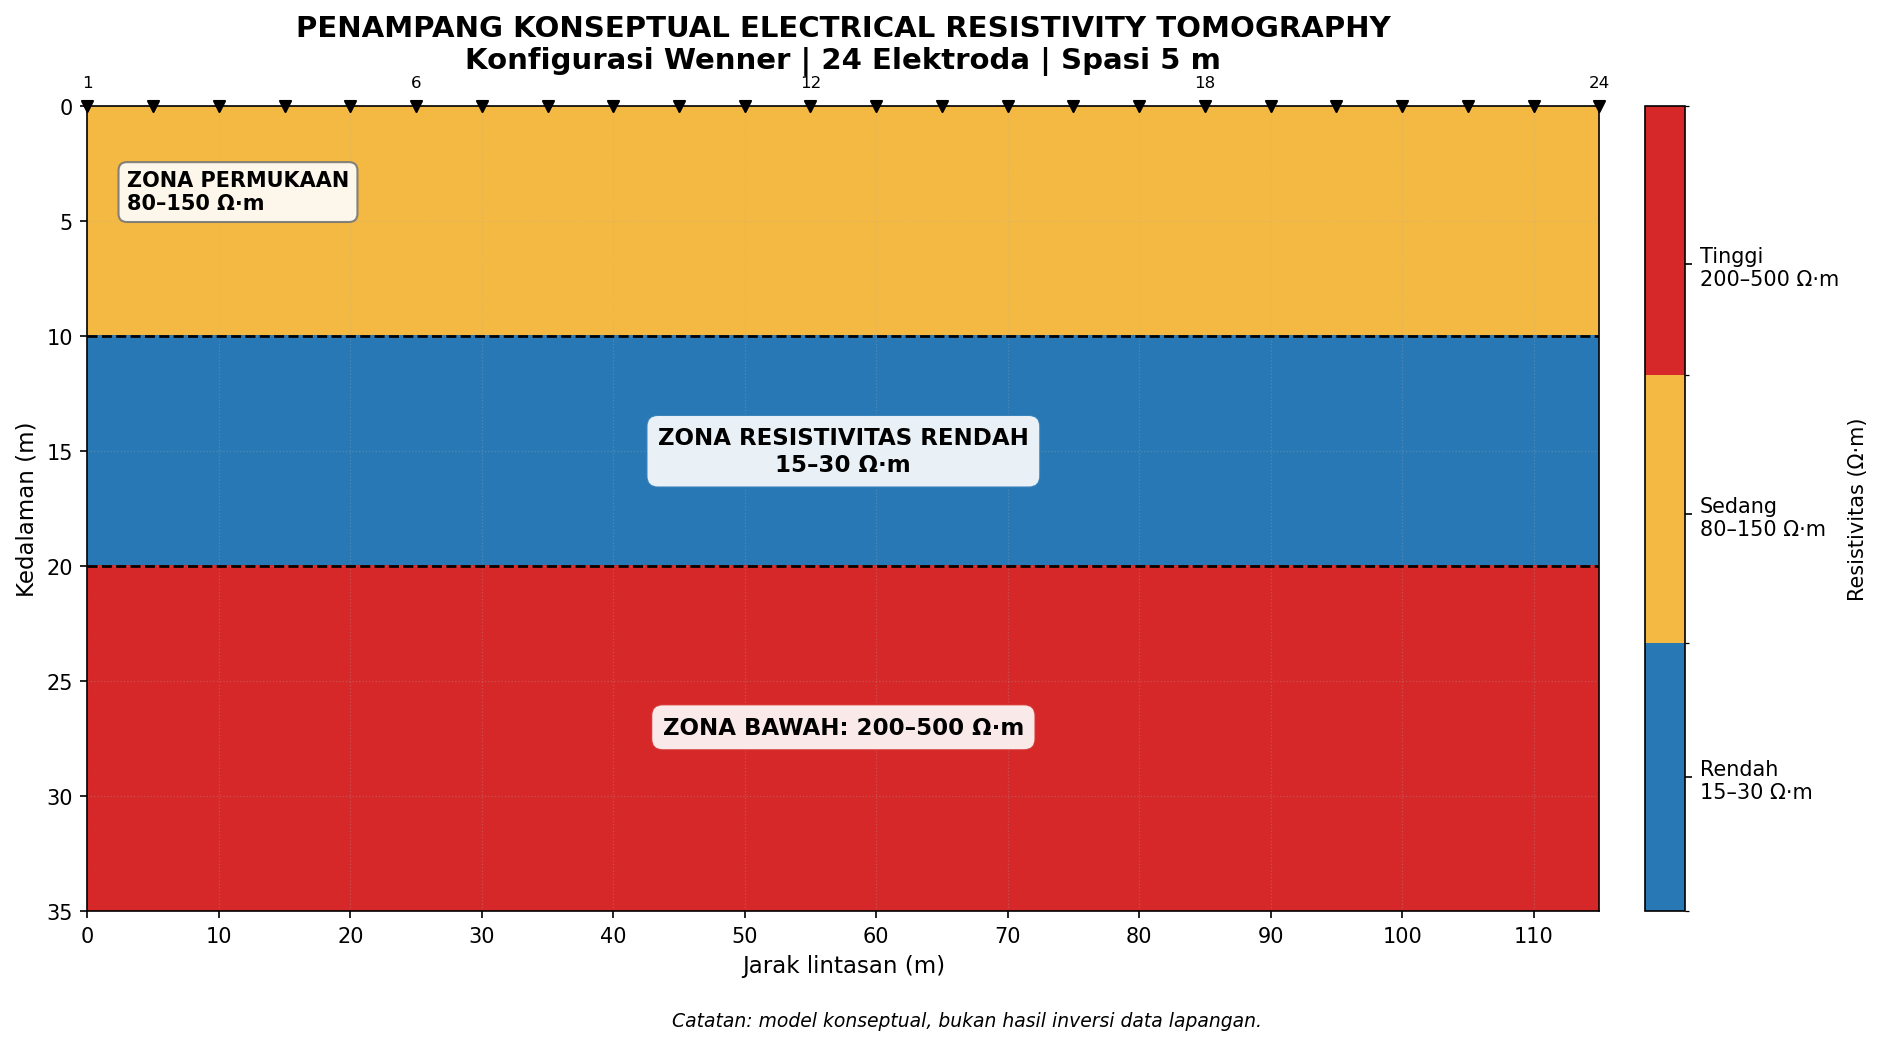

INTERPRETASI KONSEPTUAL ERT
Jumlah elektroda : 24
Spasi elektroda  : 5 m
Panjang lintasan : 115 m

Zona 1 - Permukaan (0–10 m)
Resistivitas 80–150 Ω·m.
Menunjukkan material dengan resistivitas menengah.

Zona 2 - Kedalaman 10–20 m
Resistivitas 15–30 Ω·m.
Menunjukkan material lebih konduktif.
Kemungkinan terkait air tanah, lempung,
atau fluida dengan kandungan ion tinggi.

Zona 3 - Kedalaman lebih dari 20 m
Resistivitas 200–500 Ω·m.
Menunjukkan material lebih resisif atau relatif kering.

Kesimpulan:
Terdapat tiga zona resistivitas yang berbeda.
Litologi dan keberadaan air tanah belum dapat
dipastikan tanpa data geologi atau data pendukung.

Gambar disimpan sebagai plot_ERT_Wenner.png


In [6]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# ==================================================
# 1. PARAMETER SURVEI ERT
# ==================================================
jumlah_elektroda = 24
spasi = 5  # meter
panjang_lintasan = (jumlah_elektroda - 1) * spasi  # 115 m
kedalaman_maksimum = 35  # meter

# Grid jarak dan kedalaman
x = np.linspace(0, panjang_lintasan, 300)
z = np.linspace(0, kedalaman_maksimum, 200)
X, Z = np.meshgrid(x, z)

# ==================================================
# 2. MODEL RESISTIVITAS KONSEPTUAL
# ==================================================
resistivitas = np.zeros_like(X)

# Zona permukaan: 80–150 Ohm.m, kedalaman 0–10 m
zona1 = Z < 10
resistivitas[zona1] = (
    115 + 18 * np.sin(2 * np.pi * X[zona1] / panjang_lintasan)
)

# Zona resistivitas rendah: 15–30 Ohm.m, kedalaman 10–20 m
zona2 = (Z >= 10) & (Z <= 20)
resistivitas[zona2] = (
    22 + 4 * np.sin(2 * np.pi * X[zona2] / panjang_lintasan)
)

# Zona bawah: 200–500 Ohm.m, kedalaman lebih dari 20 m
zona3 = Z > 20
resistivitas[zona3] = (
    330 + 80 * np.sin(2 * np.pi * X[zona3] / panjang_lintasan)
)

# ==================================================
# 3. MEMBUAT PLOT PENAMPANG ERT
# ==================================================
fig, ax = plt.subplots(figsize=(13, 7), dpi=150)

# Biru = rendah, jingga = sedang, merah = tinggi
warna = ["#2878B5", "#F4B942", "#D62828"]
cmap = ListedColormap(warna)
norm = BoundaryNorm([0, 50, 175, 600], cmap.N)

gambar = ax.pcolormesh(
    X, Z, resistivitas,
    cmap=cmap,
    norm=norm,
    shading="auto"
)

# Batas kedalaman zona
ax.axhline(
    10, color="black",
    linestyle="--", linewidth=1.3
)
ax.axhline(
    20, color="black",
    linestyle="--", linewidth=1.3
)

# ==================================================
# 4. LABEL SETIAP ZONA
# ==================================================
ax.text(
    3, 4.5,
    "ZONA PERMUKAAN\n80–150 Ω·m",
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        alpha=0.9,
        edgecolor="#777777",
        boxstyle="round,pad=0.4"
    )
)

ax.text(
    panjang_lintasan / 2, 15,
    "ZONA RESISTIVITAS RENDAH\n15–30 Ω·m",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        alpha=0.9,
        edgecolor="#2878B5",
        boxstyle="round,pad=0.5"
    )
)

ax.text(
    panjang_lintasan / 2, 27,
    "ZONA BAWAH: 200–500 Ω·m",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        alpha=0.9,
        edgecolor="#D62828",
        boxstyle="round,pad=0.5"
    )
)

# ==================================================
# 5. POSISI 24 ELEKTRODA
# ==================================================
posisi_elektroda = np.arange(jumlah_elektroda) * spasi

ax.scatter(
    posisi_elektroda,
    np.zeros(jumlah_elektroda),
    marker="v",
    s=28,
    color="black",
    zorder=5,
    clip_on=False
)

# Label elektroda tertentu agar grafik tetap jelas
for nomor in [1, 6, 12, 18, 24]:
    posisi = (nomor - 1) * spasi
    ax.annotate(
        str(nomor),
        xy=(posisi, 0),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

# ==================================================
# 6. COLORBAR
# ==================================================
colorbar = fig.colorbar(
    gambar,
    ax=ax,
    ticks=[25, 110, 350],
    pad=0.025
)

colorbar.ax.set_yticklabels([
    "Rendah\n15–30 Ω·m",
    "Sedang\n80–150 Ω·m",
    "Tinggi\n200–500 Ω·m"
])

colorbar.set_label(
    "Resistivitas (Ω·m)",
    fontsize=10
)

# ==================================================
# 7. FORMAT GRAFIK
# ==================================================
ax.set_title(
    "PENAMPANG KONSEPTUAL ELECTRICAL RESISTIVITY TOMOGRAPHY\n"
    "Konfigurasi Wenner | 24 Elektroda | Spasi 5 m",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Jarak lintasan (m)", fontsize=11)
ax.set_ylabel("Kedalaman (m)", fontsize=11)

ax.set_xlim(0, panjang_lintasan)
ax.set_ylim(kedalaman_maksimum, 0)

ax.set_xticks(np.arange(0, 116, 10))
ax.set_yticks(np.arange(0, 36, 5))
ax.grid(linestyle=":", linewidth=0.6, alpha=0.3)

fig.text(
    0.5, 0.015,
    "Catatan: model konseptual, bukan hasil inversi data lapangan.",
    ha="center",
    fontsize=9,
    style="italic"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Simpan gambar dengan resolusi tinggi
plt.savefig(
    "plot_ERT_Wenner.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==================================================
# 8. INTERPRETASI HASIL
# ==================================================
print("=" * 55)
print("INTERPRETASI KONSEPTUAL ERT")
print("=" * 55)

print(f"Jumlah elektroda : {jumlah_elektroda}")
print(f"Spasi elektroda  : {spasi} m")
print(f"Panjang lintasan : {panjang_lintasan} m")

print("\nZona 1 - Permukaan (0–10 m)")
print("Resistivitas 80–150 Ω·m.")
print("Menunjukkan material dengan resistivitas menengah.")

print("\nZona 2 - Kedalaman 10–20 m")
print("Resistivitas 15–30 Ω·m.")
print("Menunjukkan material lebih konduktif.")
print("Kemungkinan terkait air tanah, lempung,")
print("atau fluida dengan kandungan ion tinggi.")

print("\nZona 3 - Kedalaman lebih dari 20 m")
print("Resistivitas 200–500 Ω·m.")
print("Menunjukkan material lebih resisif atau relatif kering.")

print("\nKesimpulan:")
print("Terdapat tiga zona resistivitas yang berbeda.")
print("Litologi dan keberadaan air tanah belum dapat")
print("dipastikan tanpa data geologi atau data pendukung.")

print("\nGambar disimpan sebagai plot_ERT_Wenner.png")
print("=" * 55)


## **4. Metode Magnetik — Struktur Geologi dan Zona Intrusi**

Metode geomagnetik mengukur variasi medan magnet yang dipengaruhi oleh kontras sifat kemagnetan batuan. Pada area 2 km × 2 km dengan jarak titik 50 m, peta anomali terkoreksi menunjukkan anomali positif sekitar +250 nT di barat daya, gradien tajam sekitar 180 nT dalam jarak kurang dari 200 m di bagian tengah, dan anomali relatif rendah serta lebih homogen di timur.

Anomali positif dapat menunjukkan material dengan respons magnetik lebih kuat dibandingkan sekitarnya, tetapi tidak cukup untuk menentukan jenis batuan atau memastikan intrusi. Gradien tajam dapat mengindikasikan kontak litologi atau struktur seperti sesar, maupun perubahan lateral sifat magnetik lainnya. Anomali rendah di timur dapat berkaitan dengan material yang lebih lemah kemagnetannya. Plot berikut merupakan skema konseptual dari pola yang dijelaskan, bukan peta anomali hasil pengukuran.

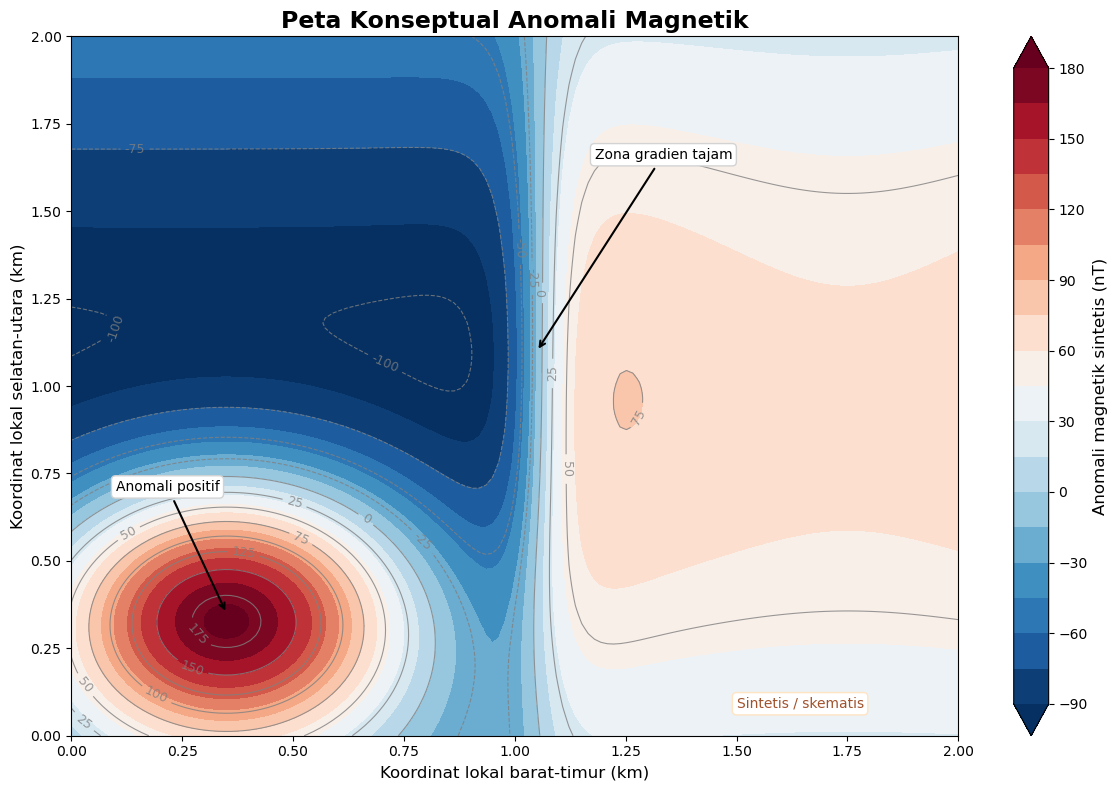


INTERPRETASI PETA KONSEPTUAL ANOMALI MAGNETIK

1. ANOMALI POSITIF DI BAGIAN BARAT DAYA
   Zona ini berada sekitar koordinat x = 0,35 km dan
   y = 0,35 km. Warna merah menunjukkan nilai anomali
   magnetik relatif tinggi dibandingkan daerah sekitarnya.
   Secara konseptual, kondisi ini dapat berkaitan dengan
   material yang memiliki sifat kemagnetan lebih kuat.
   Namun, jenis batuannya tidak dapat ditentukan hanya
   berdasarkan peta ini.

2. ZONA GRADIEN TAJAM DI BAGIAN TENGAH
   Zona ini berada di sekitar x = 1,05 km, ditandai oleh
   perubahan warna yang cepat dari biru menuju warna
   terang. Perubahan tersebut menunjukkan perubahan
   anomali magnetik yang tajam dalam jarak relatif pendek.
   Kondisi ini dapat mengindikasikan batas antara material
   dengan sifat magnetik berbeda atau kemungkinan struktur
   geologi. Interpretasi sesar masih memerlukan bukti lain.

3. ANOMALI RELATIF RENDAH DI BAGIAN BARAT
   Area berwarna biru menunjukkan nilai anomali magnetik
   relatif rend

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. MEMBUAT GRID KOORDINAT
# ==========================================
n = 140
x = np.linspace(0, 2, n)
y = np.linspace(0, 2, n)
X, Y = np.meshgrid(x, y)

# ==========================================
# 2. MEMBUAT MODEL ANOMALI MAGNETIK SINTETIS
# ==========================================

# Anomali dasar
field = -10 * np.ones_like(X)

# Anomali positif di bagian barat daya
field += 260 * np.exp(
    -(((X - 0.35) / 0.42) ** 2
      + ((Y - 0.35) / 0.40) ** 2)
)

# Zona gradien tajam di bagian tengah
field += 95 * np.tanh((X - 1.05) / 0.08) * np.exp(
    -((Y - 1.0) / 1.1) ** 2
)

# Anomali negatif di bagian timur
field -= 20 * np.exp(
    -(((X - 1.75) / 0.55) ** 2
      + ((Y - 1.1) / 0.75) ** 2)
)

# ==========================================
# 3. MEMBUAT PETA ANOMALI MAGNETIK
# ==========================================
plt.figure(figsize=(12, 8))

# Kontur warna
cf = plt.contourf(
    X, Y, field,
    levels=25,
    cmap="RdBu_r",
    extend="both"
)

# Garis kontur
contours = plt.contour(
    X, Y, field,
    levels=12,
    colors="gray",
    linewidths=0.8,
    alpha=0.8
)

plt.clabel(
    contours,
    inline=True,
    fontsize=9,
    fmt="%.0f"
)

# Skala warna
cbar = plt.colorbar(cf)
cbar.set_label("Anomali magnetik sintetis (nT)", fontsize=12)

# ==========================================
# 4. MENAMBAHKAN ANOTASI
# ==========================================

# Anomali positif
plt.annotate(
    "Anomali positif",
    xy=(0.35, 0.35),
    xytext=(0.10, 0.70),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="lightgray")
)

# Zona gradien tajam
plt.annotate(
    "Zona gradien tajam",
    xy=(1.05, 1.10),
    xytext=(1.18, 1.65),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="lightgray")
)

# Keterangan model
plt.text(
    1.50, 0.08,
    "Sintetis / skematis",
    color="sienna",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="bisque")
)

# Judul dan sumbu
plt.title("Peta Konseptual Anomali Magnetik", fontsize=17, weight="bold")
plt.xlabel("Koordinat lokal barat-timur (km)", fontsize=12)
plt.ylabel("Koordinat lokal selatan-utara (km)", fontsize=12)

plt.xlim(0, 2)
plt.ylim(0, 2)
plt.tight_layout()
plt.show()

# ==========================================
# 5. INTERPRETASI HASIL PLOT
# ==========================================

print("\n" + "=" * 55)
print("INTERPRETASI PETA KONSEPTUAL ANOMALI MAGNETIK")
print("=" * 55)

print("""
1. ANOMALI POSITIF DI BAGIAN BARAT DAYA
   Zona ini berada sekitar koordinat x = 0,35 km dan
   y = 0,35 km. Warna merah menunjukkan nilai anomali
   magnetik relatif tinggi dibandingkan daerah sekitarnya.
   Secara konseptual, kondisi ini dapat berkaitan dengan
   material yang memiliki sifat kemagnetan lebih kuat.
   Namun, jenis batuannya tidak dapat ditentukan hanya
   berdasarkan peta ini.

2. ZONA GRADIEN TAJAM DI BAGIAN TENGAH
   Zona ini berada di sekitar x = 1,05 km, ditandai oleh
   perubahan warna yang cepat dari biru menuju warna
   terang. Perubahan tersebut menunjukkan perubahan
   anomali magnetik yang tajam dalam jarak relatif pendek.
   Kondisi ini dapat mengindikasikan batas antara material
   dengan sifat magnetik berbeda atau kemungkinan struktur
   geologi. Interpretasi sesar masih memerlukan bukti lain.

3. ANOMALI RELATIF RENDAH DI BAGIAN BARAT
   Area berwarna biru menunjukkan nilai anomali magnetik
   relatif rendah. Hal ini dapat berkaitan dengan material
   yang memberikan respons magnetik lebih lemah dibandingkan
   zona anomali positif. Penyebab pastinya tidak dapat
   ditentukan tanpa data geologi pendukung.

4. KONDISI BAGIAN TIMUR
   Bagian timur memperlihatkan anomali yang relatif lebih
   positif daripada zona biru di bagian barat, tetapi tidak
   setinggi pusat anomali positif di barat daya. Pola ini
   menunjukkan perbedaan respons magnetik antarzona.

KESIMPULAN
   Peta memperlihatkan tiga pola utama, yaitu anomali
   positif di barat daya, gradien tajam di bagian tengah,
   dan anomali relatif rendah di bagian barat. Pola tersebut
   dapat digunakan untuk menjelaskan variasi respons
   magnetik secara konseptual. Karena data bersifat sintetis,
   peta ini tidak mewakili hasil survei lapangan dan tidak
   dapat digunakan untuk menentukan kedalaman atau jenis
   batuan secara pasti.
""")


## **5.  Metode Gravitasi — Cekungan Sedimen dan Struktur Bawah Permukaan**

Metode gravitasi mengukur variasi percepatan gravitasi akibat perbedaan densitas bawah permukaan. Setelah koreksi yang diperlukan—seperti drift, lintang, elevasi, dan Bouguer—data dapat dianalisis sebagai anomali Bouguer. Pada soal, area survei berukuran 5 km × 5 km dengan jarak titik sekitar 250 m. Bagian tengah menunjukkan anomali relatif rendah sekitar −35 mGal, sedangkan bagian utara dan selatan meningkat bertahap hingga sekitar −10 mGal. Di timur terdapat perubahan anomali yang relatif tajam dalam jarak sekitar 1 km.

Anomali rendah di tengah konsisten dengan kemungkinan material berdensitas relatif rendah dan dapat mendukung dugaan cekungan sedimen, tetapi penyebab lain juga mungkin. Perubahan tajam di timur dapat mencerminkan batas densitas atau struktur geologi. Tanpa pemodelan dan parameter tambahan, kedalaman serta ketebalan cekungan tidak dapat ditentukan secara pasti. Plot di bawah adalah skema konseptual yang memvisualisasikan pola anomali yang disebutkan, bukan peta Bouguer lapangan.

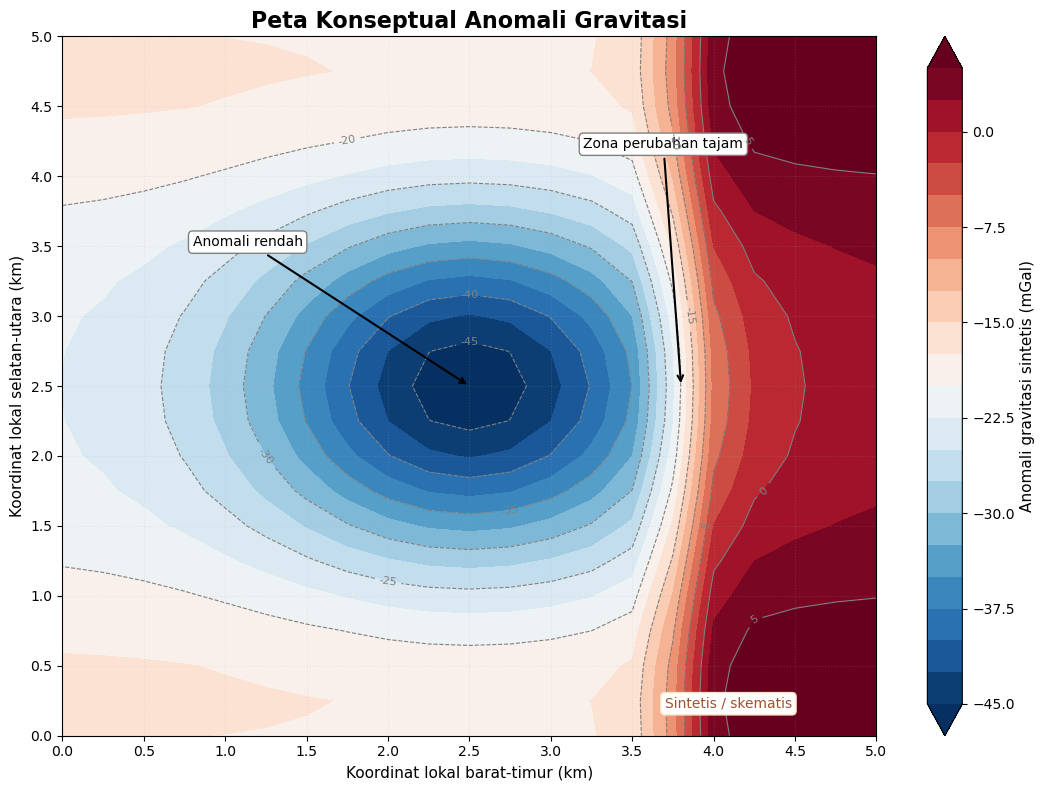


INTERPRETASI PETA KONSEPTUAL ANOMALI GRAVITASI

1. ANOMALI RENDAH DI BAGIAN TENGAH
   Bagian tengah area survei menunjukkan anomali gravitasi
   relatif rendah, dengan target konseptual sekitar -35 mGal.
   Anomali ini dapat mengindikasikan material berdensitas
   relatif rendah dibandingkan daerah sekitarnya. Salah satu
   kemungkinan interpretasinya adalah cekungan sedimen.
   Namun, penyebab lain juga mungkin sehingga perlu data
   geologi dan pemodelan tambahan.

2. PENINGKATAN ANOMALI DI UTARA DAN SELATAN
   Nilai anomali meningkat secara bertahap dari bagian tengah
   menuju utara dan selatan, mendekati -10 mGal sesuai
   gambaran soal. Pola ini menunjukkan perubahan respons
   gravitasi secara spasial dan dapat berkaitan dengan
   perbedaan densitas material bawah permukaan.

3. PERUBAHAN TAJAM DI BAGIAN TIMUR
   Bagian timur memperlihatkan perubahan anomali dalam jarak
   relatif pendek, sekitar 1 km. Kondisi ini dapat menunjukkan
   batas antara material dengan densitas berbe

In [9]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. MEMBUAT GRID AREA SURVEI 5 KM x 5 KM
# ==========================================
jarak = 0.25  # Jarak antar titik survei 250 meter
x = np.arange(0, 5 + jarak, jarak)
y = np.arange(0, 5 + jarak, jarak)
X, Y = np.meshgrid(x, y)

# ==========================================
# 2. MEMBUAT MODEL ANOMALI GRAVITASI SINTETIS
# ==========================================

# Anomali dasar
anomali = -10 * np.ones_like(X)

# Anomali rendah di bagian tengah, sekitar -35 mGal
anomali -= 25 * np.exp(
    -(((X - 2.5) / 1.3) ** 2
      + ((Y - 2.5) / 1.2) ** 2)
)

# Peningkatan anomali bertahap ke utara dan selatan
anomali += 5 * np.exp(-((Y - 0.3) / 1.0) ** 2)
anomali += 5 * np.exp(-((Y - 4.7) / 1.0) ** 2)

# Perubahan anomali relatif tajam di bagian timur
anomali += 12 * np.tanh((X - 3.8) / 0.18)

# ==========================================
# 3. MEMBUAT PETA KONTUR ANOMALI GRAVITASI
# ==========================================
plt.figure(figsize=(11, 8))

peta = plt.contourf(
    X, Y, anomali,
    levels=25,
    cmap="RdBu_r",
    extend="both"
)

# Garis kontur
kontur = plt.contour(
    X, Y, anomali,
    levels=12,
    colors="gray",
    linewidths=0.8
)

plt.clabel(kontur, inline=True, fontsize=8, fmt="%.0f")

# Skala warna
cbar = plt.colorbar(peta)
cbar.set_label("Anomali gravitasi sintetis (mGal)", fontsize=11)

# ==========================================
# 4. ANOTASI ZONA PENTING
# ==========================================

# Anomali rendah di tengah
plt.annotate(
    "Anomali rendah",
    xy=(2.5, 2.5),
    xytext=(0.8, 3.5),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray")
)

# Perubahan tajam di timur
plt.annotate(
    "Zona perubahan tajam",
    xy=(3.8, 2.5),
    xytext=(3.2, 4.2),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray")
)

# Keterangan skema
plt.text(
    3.7, 0.2,
    "Sintetis / skematis",
    fontsize=10,
    color="sienna",
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="bisque")
)

# Judul dan sumbu
plt.title("Peta Konseptual Anomali Gravitasi", fontsize=16, weight="bold")
plt.xlabel("Koordinat lokal barat-timur (km)", fontsize=11)
plt.ylabel("Koordinat lokal selatan-utara (km)", fontsize=11)

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xticks(np.arange(0, 5.25, 0.5))
plt.yticks(np.arange(0, 5.25, 0.5))
plt.grid(alpha=0.2, linestyle=":")
plt.tight_layout()
plt.show()

# ==========================================
# 5. INTERPRETASI HASIL
# ==========================================

print("\n" + "=" * 55)
print("INTERPRETASI PETA KONSEPTUAL ANOMALI GRAVITASI")
print("=" * 55)

print("""
1. ANOMALI RENDAH DI BAGIAN TENGAH
   Bagian tengah area survei menunjukkan anomali gravitasi
   relatif rendah, dengan target konseptual sekitar -35 mGal.
   Anomali ini dapat mengindikasikan material berdensitas
   relatif rendah dibandingkan daerah sekitarnya. Salah satu
   kemungkinan interpretasinya adalah cekungan sedimen.
   Namun, penyebab lain juga mungkin sehingga perlu data
   geologi dan pemodelan tambahan.

2. PENINGKATAN ANOMALI DI UTARA DAN SELATAN
   Nilai anomali meningkat secara bertahap dari bagian tengah
   menuju utara dan selatan, mendekati -10 mGal sesuai
   gambaran soal. Pola ini menunjukkan perubahan respons
   gravitasi secara spasial dan dapat berkaitan dengan
   perbedaan densitas material bawah permukaan.

3. PERUBAHAN TAJAM DI BAGIAN TIMUR
   Bagian timur memperlihatkan perubahan anomali dalam jarak
   relatif pendek, sekitar 1 km. Kondisi ini dapat menunjukkan
   batas antara material dengan densitas berbeda atau
   kemungkinan struktur geologi. Akan tetapi, pola ini saja
   belum cukup untuk memastikan keberadaan sesar.

4. KETERBATASAN INTERPRETASI
   Kedalaman, ketebalan, dan bentuk cekungan tidak dapat
   ditentukan secara pasti hanya dari peta kontur. Diperlukan
   pemodelan gravitasi, informasi densitas batuan, topografi,
   serta data geologi pendukung.

KESIMPULAN
   Peta konseptual memperlihatkan anomali rendah di bagian
   tengah, peningkatan anomali ke utara dan selatan, serta
   perubahan relatif tajam di timur. Pola tersebut dapat
   menjadi dasar interpretasi awal variasi densitas bawah
   permukaan. Peta ini bersifat sintetis dan bukan hasil
   pengukuran gravitasi lapangan.
""")
